# Gradient Descent Optimization Project


### 1. Cost Function & Derivative Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Cost function: J(w) = (w - 4)^2 + 3
# Global minimum is at w = 4 where J(4) = 3
def cost_func(w):
    return (w - 4)**2 + 3

# Derivative: dJ/dw = 2 * (w - 4)
def grad_func(w):
    return 2 * (w - 4)

print("Cost Function: J(w) = (w - 4)^2 + 3")
print("Gradient:      dJ/dw = 2*(w - 4)")
print("Expected Minimum: w = 4.0, Cost = 3.0")


Cost Function: J(w) = (w - 4)^2 + 3
Gradient:      dJ/dw = 2*(w - 4)
Expected Minimum: w = 4.0, Cost = 3.0


### 2. Gradient Descent Algorithm


In [2]:
# Parameters
initial_w = -2.0      # starting point far from minimum
learning_rate = 0.15  # step size alpha
iterations = 25       # number of optimization steps

history_iter = []
history_w = []
history_grad = []
history_cost = []

current_w = initial_w

for i in range(iterations + 1):
    cost = cost_func(current_w)
    grad = grad_func(current_w)
    
    history_iter.append(i)
    history_w.append(current_w)
    history_grad.append(grad)
    history_cost.append(cost)
    
    # Gradient descent update rule: w_new = w_old - alpha * gradient
    current_w = current_w - learning_rate * grad

print(f"Initial w: {initial_w:.2f} | Initial Cost: {history_cost[0]:.2f}")
print(f"Final w:   {history_w[-1]:.4f} | Final Cost:   {history_cost[-1]:.4f}")


Initial w: -2.00 | Initial Cost: 39.00
Final w:   3.9992 | Final Cost:   3.0000


### 3. Step-by-Step Optimization History


In [3]:
print("Iter |   Weight (w)   |    Gradient    |     Cost J(w)")
print("-" * 52)
# Display first 6 steps and last step
for i in range(min(7, len(history_iter))):
    print(f"{history_iter[i]:^4} | {history_w[i]:^14.4f} | {history_grad[i]:^14.4f} | {history_cost[i]:^13.4f}")
print(" ...")
print(f"{history_iter[-1]:^4} | {history_w[-1]:^14.4f} | {history_grad[-1]:^14.4f} | {history_cost[-1]:^13.4f}")


Iter |   Weight (w)   |    Gradient    |     Cost J(w)
----------------------------------------------------
 0   |    -2.0000     |    -12.0000    |    39.0000   
 1   |    -0.2000     |    -8.4000     |    20.6400   
 2   |     1.0600     |    -5.8800     |    11.6436   
 3   |     1.9420     |    -4.1160     |    7.2354    
 4   |     2.5594     |    -2.8812     |    5.0753    
 5   |     2.9916     |    -2.0168     |    4.0169    
 6   |     3.2941     |    -1.4118     |    3.4983    
 ...
 25  |     3.9992     |    -0.0016     |    3.0000    


### 4. Visualizing Gradient Descent Trajectory on Cost Curve


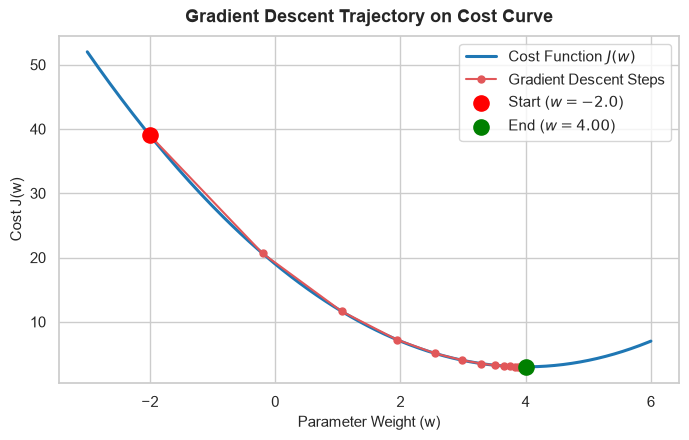

In [4]:
w_range = np.linspace(-3, 6, 200)
cost_curve = cost_func(w_range)

plt.figure(figsize=(8, 4.5))
plt.plot(w_range, cost_curve, color='#1f77b4', linewidth=2.2, label='Cost Function $J(w)$')

# Plot path taken by gradient descent
plt.plot(history_w, history_cost, 'o-', color='#e15759', markersize=5, linewidth=1.5, label='Gradient Descent Steps')
plt.scatter([history_w[0]], [history_cost[0]], color='red', s=120, zorder=5, label='Start ($w=-2.0$)')
plt.scatter([history_w[-1]], [history_cost[-1]], color='green', s=120, zorder=5, label=f'End ($w={history_w[-1]:.2f}$)')

plt.title("Gradient Descent Trajectory on Cost Curve", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Parameter Weight (w)", fontsize=11)
plt.ylabel("Cost J(w)", fontsize=11)
plt.legend()
plt.show()


### 5. Learning Curve (Cost vs Iterations)


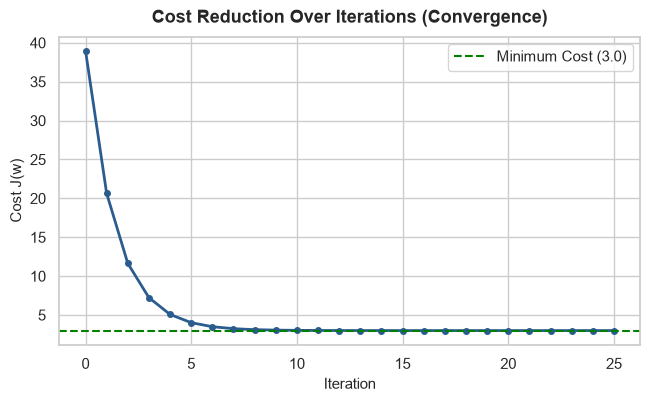

In [5]:
plt.figure(figsize=(7.5, 4))
plt.plot(history_iter, history_cost, marker='o', color='#2b5c8f', linewidth=2, markersize=4)
plt.axhline(3.0, color='green', linestyle='--', label='Minimum Cost (3.0)')
plt.title("Cost Reduction Over Iterations (Convergence)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Cost J(w)", fontsize=11)
plt.legend()
plt.show()


### 6. Comparison of Different Learning Rates (Alpha)


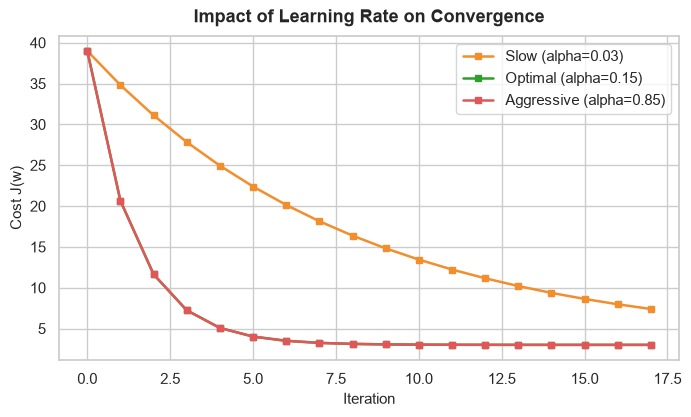

In [6]:
learning_rates = [0.03, 0.15, 0.85]
labels = ['Slow (alpha=0.03)', 'Optimal (alpha=0.15)', 'Aggressive (alpha=0.85)']
colors = ['#f28e2b', '#2ca02c', '#e15759']

plt.figure(figsize=(8, 4.2))

for lr, lbl, col in zip(learning_rates, labels, colors):
    w_val = -2.0
    c_hist = []
    for _ in range(18):
        c_hist.append(cost_func(w_val))
        w_val = w_val - lr * grad_func(w_val)
    plt.plot(range(18), c_hist, marker='s', label=lbl, color=col, linewidth=1.8, markersize=4)

plt.title("Impact of Learning Rate on Convergence", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Cost J(w)", fontsize=11)
plt.legend()
plt.show()


### 7. Export Gradient Descent History to CSV


In [7]:
# Create summary array
summary_data = np.column_stack([
    history_iter,
    np.round(history_w, 4),
    np.round(history_grad, 4),
    np.round(history_cost, 4)
])

csv_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(csv_dir, exist_ok=True)
csv_path = os.path.join(csv_dir, "gradient_descent_history.csv")

np.savetxt(
    csv_path,
    summary_data,
    delimiter=",",
    header="Iteration,Weight,Gradient,Cost",
    fmt=["%d", "%.4f", "%.4f", "%.4f"],
    comments=""
)
print(f"Gradient descent history saved successfully to: {csv_path}")


Gradient descent history saved successfully to: csv\gradient_descent_history.csv
